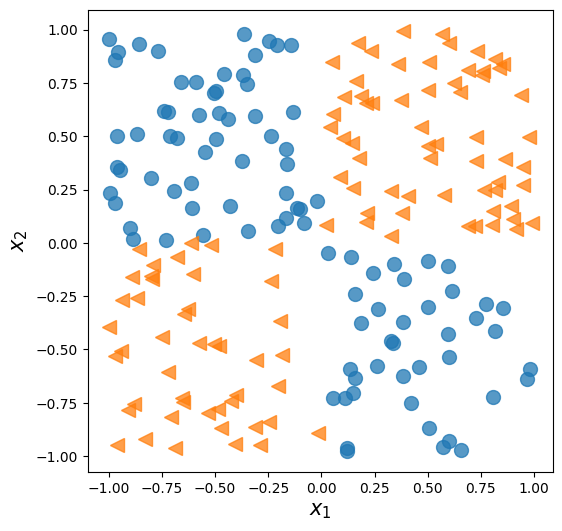

In [1]:
# week7_1.txt
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(1)

x = np.random.uniform(low=-1, high=1, size=(200, 2))
y = np.ones(len(x))
y[x[:, 0] * x[:, 1]<0] = 0

x_train = x[:100, :]
y_train = y[:100]
x_valid = x[100:, :]
y_valid = y[100:]

fig = plt.figure(figsize=(6, 6))
plt.plot(x[y==0, 0], 
         x[y==0, 1], 'o', alpha=0.75, markersize=10)
plt.plot(x[y==1, 0], 
         x[y==1, 1], '<', alpha=0.75, markersize=10)
plt.xlabel(r'$x_1$', size=15)
plt.ylabel(r'$x_2$', size=15)
plt.show()

In [2]:
import tensorflow as tf
import numpy as np

tf.random.set_seed(1)
np.random.seed(1)

# 로지스틱 회귀 모델
model_logistic = tf.keras.Sequential()
model_logistic.add(tf.keras.layers.Dense(units=1,
                                input_shape=(2,),
                                kernel_initializer=tf.keras.initializers.GlorotNormal(),
                                activation='sigmoid'))

model_logistic.summary()

/opt/miniconda3/envs/mldl/lib/python3.10/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3 (12.00 B)

 Trainable params: 3 (12.00 B)

 Non-trainable params: 0 (0.00 B)

In [3]:
model_logistic.compile(optimizer=tf.keras.optimizers.SGD(),
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=[tf.keras.metrics.BinaryAccuracy()])

In [4]:
hist = model_logistic.fit(x_train, y_train,
                 validation_data=(x_valid, y_valid),
                 epochs=200, batch_size=2, verbose=1)

Epoch 1/200


 1/50 ━━━━━━━━━━━━━━━━━━━━ 3s 66ms/step - binary_accuracy: 0.0000e+00 - loss: 1.0921

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.4100 - loss: 0.7539 - val_binary_accuracy: 0.4000 - val_loss: 0.7724


Epoch 2/200


 1/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - binary_accuracy: 0.0000e+00 - loss: 1.0656

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 870us/step - binary_accuracy: 0.4000 - loss: 0.7480 - val_binary_accuracy: 0.4000 - val_loss: 0.7657


... (590 outputs left out)

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 736us/step - binary_accuracy: 0.6600 - loss: 0.6858 - val_binary_accuracy: 0.7100 - val_loss: 0.6790


Epoch 200/200


 1/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - binary_accuracy: 1.0000 - loss: 0.6183

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 735us/step - binary_accuracy: 0.6600 - loss: 0.6858 - val_binary_accuracy: 0.7100 - val_loss: 0.6790


In [5]:
history = hist.history

In [6]:
print(type(history))
print(history.keys())

<class 'dict'>
dict_keys(['binary_accuracy', 'loss', 'val_binary_accuracy', 'val_loss'])


In [7]:
print(len(history['loss']))

200


In [8]:
!pip install mlxtend

INFO: pip is looking at multiple versions of mlxtend to determine which version is compatible with other requirements. This could take a while.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.4 MB ? eta -:--:--

   ━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.3/1.4 MB ? eta -:--:--

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 5.6 MB/s  0:00:00


    1/20000 ━━━━━━━━━━━━━━━━━━━━ 6:58 21ms/step

  299/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 168us/step 

  593/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 169us/step

  889/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 169us/step

 1187/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 169us/step

 1487/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 169us/step

... (57 outputs left out)

19100/20000 ━━━━━━━━━━━━━━━━━━━━ 0s 165us/step

19404/20000 ━━━━━━━━━━━━━━━━━━━━ 0s 165us/step

19708/20000 ━━━━━━━━━━━━━━━━━━━━ 0s 165us/step

20000/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 166us/step


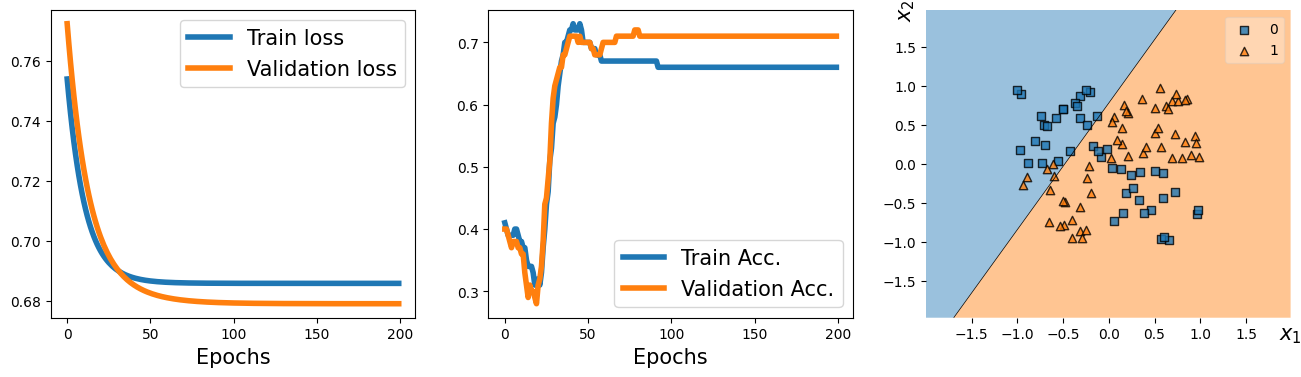

In [9]:
# week7_2.txt
from mlxtend.plotting import plot_decision_regions

history = hist.history

fig = plt.figure(figsize=(16, 4))
ax = fig.add_subplot(1, 3, 1)
plt.plot(history['loss'], lw=4)
plt.plot(history['val_loss'], lw=4)
plt.legend(['Train loss', 'Validation loss'], fontsize=15)
ax.set_xlabel('Epochs', size=15)

ax = fig.add_subplot(1, 3, 2)
plt.plot(history['binary_accuracy'], lw=4)
plt.plot(history['val_binary_accuracy'], lw=4)
plt.legend(['Train Acc.', 'Validation Acc.'], fontsize=15)
ax.set_xlabel('Epochs', size=15)

ax = fig.add_subplot(1, 3, 3)
plot_decision_regions(X=x_valid, y=y_valid.astype(np.int64),
                      clf=model_logistic)
ax.set_xlabel(r'$x_1$', size=15)
ax.xaxis.set_label_coords(1, -0.025)
ax.set_ylabel(r'$x_2$', size=15)
ax.yaxis.set_label_coords(-0.025, 1)

plt.show()

In [10]:
tf.random.set_seed(1)

model_mlp = tf.keras.Sequential()
model_mlp.add(tf.keras.layers.Dense(units=4, input_shape=(2,), activation='relu'))
model_mlp.add(tf.keras.layers.Dense(units=4, activation='relu'))
model_mlp.add(tf.keras.layers.Dense(units=4, activation='relu'))
model_mlp.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

model_mlp.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57 (228.00 B)

 Trainable params: 57 (228.00 B)

 Non-trainable params: 0 (0.00 B)

In [11]:
## 컴파일:
model_mlp.compile(optimizer=tf.keras.optimizers.SGD(),
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=[tf.keras.metrics.BinaryAccuracy()])

## 훈련:
hist = model_mlp.fit(x_train, y_train,
                     validation_data=(x_valid, y_valid),
                     epochs=200, batch_size=2, verbose=1)

# 학습 진행내용이 저장된 history 딕셔너리
history = hist.history

Epoch 1/200


 1/50 ━━━━━━━━━━━━━━━━━━━━ 8s 172ms/step - binary_accuracy: 0.5000 - loss: 0.6636

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.5000 - loss: 0.6606 - val_binary_accuracy: 0.5600 - val_loss: 0.6528


Epoch 2/200


 1/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - binary_accuracy: 0.5000 - loss: 0.6605

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 845us/step - binary_accuracy: 0.5600 - loss: 0.6519 - val_binary_accuracy: 0.6700 - val_loss: 0.6456


... (590 outputs left out)

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 771us/step - binary_accuracy: 1.0000 - loss: 0.0423 - val_binary_accuracy: 0.9600 - val_loss: 0.1275


Epoch 200/200


 1/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - binary_accuracy: 1.0000 - loss: 0.3203

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 772us/step - binary_accuracy: 1.0000 - loss: 0.0419 - val_binary_accuracy: 0.9600 - val_loss: 0.1275


    1/20000 ━━━━━━━━━━━━━━━━━━━━ 7:40 23ms/step

  272/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 185us/step 

  584/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 172us/step

  858/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 175us/step

 1129/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 178us/step

 1421/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 176us/step

... (61 outputs left out)

19254/20000 ━━━━━━━━━━━━━━━━━━━━ 0s 174us/step

19537/20000 ━━━━━━━━━━━━━━━━━━━━ 0s 174us/step

19817/20000 ━━━━━━━━━━━━━━━━━━━━ 0s 174us/step

20000/20000 ━━━━━━━━━━━━━━━━━━━━ 4s 175us/step


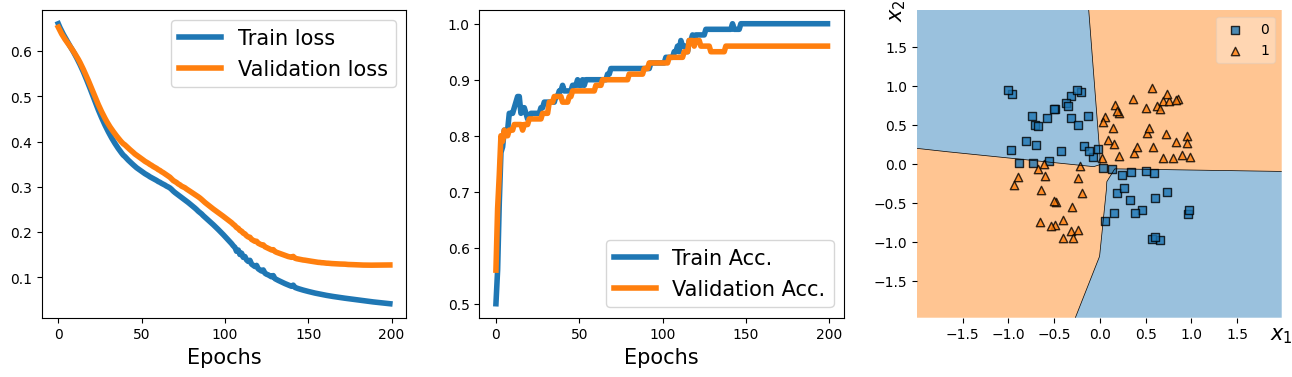

In [12]:
# week7_3.txt
fig = plt.figure(figsize=(16, 4))
ax = fig.add_subplot(1, 3, 1)
plt.plot(history['loss'], lw=4)
plt.plot(history['val_loss'], lw=4)
plt.legend(['Train loss', 'Validation loss'], fontsize=15)
ax.set_xlabel('Epochs', size=15)

ax = fig.add_subplot(1, 3, 2)
plt.plot(history['binary_accuracy'], lw=4)
plt.plot(history['val_binary_accuracy'], lw=4)
plt.legend(['Train Acc.', 'Validation Acc.'], fontsize=15)
ax.set_xlabel('Epochs', size=15)

ax = fig.add_subplot(1, 3, 3)
plot_decision_regions(X=x_valid, y=y_valid.astype(np.int64),
                      clf=model_mlp)
ax.set_xlabel(r'$x_1$', size=15)
ax.xaxis.set_label_coords(1, -0.025)
ax.set_ylabel(r'$x_2$', size=15)
ax.yaxis.set_label_coords(-0.025, 1)
# plt.savefig('images/14_3.png', dpi=300)
plt.show()

In [13]:
tf.random.set_seed(1)

## 입력층
inputs = tf.keras.Input(shape=(2,))

## 은닉층
h1 = tf.keras.layers.Dense(units=4, activation='relu')(inputs)
h2 = tf.keras.layers.Dense(units=4, activation='relu')(h1) # 입력으로 h1 의 출력을 사용
h3 = tf.keras.layers.Dense(units=4, activation='relu')(h2)

## 출력층
outputs = tf.keras.layers.Dense(units=1, activation='sigmoid')(h3)

## 모델 만들기
model_mlp2 = tf.keras.Model(inputs=inputs, outputs=outputs)

model_mlp2.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57 (228.00 B)

 Trainable params: 57 (228.00 B)

 Non-trainable params: 0 (0.00 B)

In [14]:
## 컴파일
model_mlp2.compile(optimizer=tf.keras.optimizers.SGD(),
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=[tf.keras.metrics.BinaryAccuracy()])

## 훈련
hist = model_mlp2.fit(x_train, y_train,
                     validation_data=(x_valid, y_valid),
                     epochs=200, batch_size=2, verbose=1)

Epoch 1/200


 1/50 ━━━━━━━━━━━━━━━━━━━━ 4s 83ms/step - binary_accuracy: 0.5000 - loss: 0.7199

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.5300 - loss: 0.6514 - val_binary_accuracy: 0.5500 - val_loss: 0.6638


Epoch 2/200


 1/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - binary_accuracy: 0.5000 - loss: 0.7302

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 842us/step - binary_accuracy: 0.5200 - loss: 0.6459 - val_binary_accuracy: 0.5000 - val_loss: 0.6606


... (590 outputs left out)

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 774us/step - binary_accuracy: 1.0000 - loss: 0.0290 - val_binary_accuracy: 0.9500 - val_loss: 0.1149


Epoch 200/200


 1/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - binary_accuracy: 1.0000 - loss: 0.2402

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 775us/step - binary_accuracy: 1.0000 - loss: 0.0288 - val_binary_accuracy: 0.9500 - val_loss: 0.1155


    1/20000 ━━━━━━━━━━━━━━━━━━━━ 6:32 20ms/step

  268/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 188us/step 

  548/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 183us/step

  827/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 182us/step

 1105/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 182us/step

 1390/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 180us/step

... (62 outputs left out)

19195/20000 ━━━━━━━━━━━━━━━━━━━━ 0s 177us/step

19480/20000 ━━━━━━━━━━━━━━━━━━━━ 0s 177us/step

19765/20000 ━━━━━━━━━━━━━━━━━━━━ 0s 177us/step

20000/20000 ━━━━━━━━━━━━━━━━━━━━ 4s 178us/step


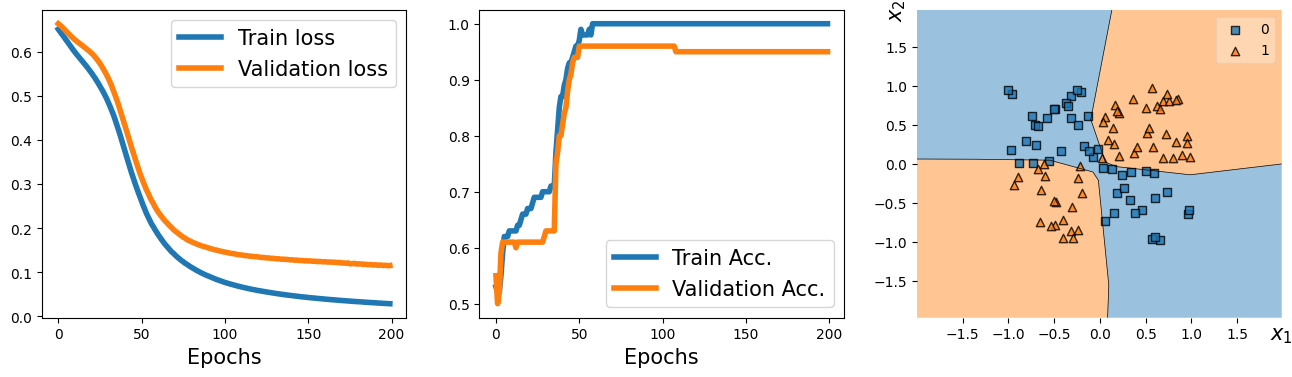

In [15]:
# week7_4.txt
history = hist.history

fig = plt.figure(figsize=(16, 4))
ax = fig.add_subplot(1, 3, 1)
plt.plot(history['loss'], lw=4)
plt.plot(history['val_loss'], lw=4)
plt.legend(['Train loss', 'Validation loss'], fontsize=15)
ax.set_xlabel('Epochs', size=15)

ax = fig.add_subplot(1, 3, 2)
plt.plot(history['binary_accuracy'], lw=4)
plt.plot(history['val_binary_accuracy'], lw=4)
plt.legend(['Train Acc.', 'Validation Acc.'], fontsize=15)
ax.set_xlabel('Epochs', size=15)

ax = fig.add_subplot(1, 3, 3)
plot_decision_regions(X=x_valid, y=y_valid.astype(np.int64),
                      clf=model_mlp2)
ax.set_xlabel(r'$x_1$', size=15)
ax.xaxis.set_label_coords(1, -0.025)
ax.set_ylabel(r'$x_2$', size=15)
ax.yaxis.set_label_coords(-0.025, 1)
plt.show()

In [16]:
class MyModel(tf.keras.Model):
    def __init__(self):
        super(MyModel, self).__init__()
        self.hidden_1 = tf.keras.layers.Dense(units=4, activation='relu')
        self.hidden_2 = tf.keras.layers.Dense(units=4, activation='relu')
        self.hidden_3 = tf.keras.layers.Dense(units=4, activation='relu')
        self.output_layer = tf.keras.layers.Dense(units=1, activation='sigmoid')

    def call(self, inputs):
        # 모든 은닉층의 출력은 동일한 변수 h 를 사용하여 가독성을 높임
        h = self.hidden_1(inputs)
        h = self.hidden_2(h)
        h = self.hidden_3(h)
        return self.output_layer(h)

In [17]:
tf.random.set_seed(1)

model_mlp3 = MyModel()
model_mlp3.build(input_shape=(None, 2))

model_mlp3.summary()

/opt/miniconda3/envs/mldl/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'my_model', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Model: "my_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [18]:
## 컴파일
model_mlp3.compile(optimizer=tf.keras.optimizers.SGD(),
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=[tf.keras.metrics.BinaryAccuracy()])

## 훈련
hist = model_mlp3.fit(x_train, y_train,
                     validation_data=(x_valid, y_valid),
                     epochs=200, batch_size=2, verbose=1)

Epoch 1/200


 1/50 ━━━━━━━━━━━━━━━━━━━━ 9s 194ms/step - binary_accuracy: 1.0000 - loss: 0.6389

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - binary_accuracy: 0.6400 - loss: 0.6910 - val_binary_accuracy: 0.6500 - val_loss: 0.6805


Epoch 2/200


 1/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - binary_accuracy: 1.0000 - loss: 0.6364

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 847us/step - binary_accuracy: 0.6800 - loss: 0.6838 - val_binary_accuracy: 0.7100 - val_loss: 0.6747


... (590 outputs left out)

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 783us/step - binary_accuracy: 1.0000 - loss: 0.0201 - val_binary_accuracy: 0.9600 - val_loss: 0.0824


Epoch 200/200


 1/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - binary_accuracy: 1.0000 - loss: 0.1651

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 777us/step - binary_accuracy: 1.0000 - loss: 0.0199 - val_binary_accuracy: 0.9600 - val_loss: 0.0823


    1/20000 ━━━━━━━━━━━━━━━━━━━━ 6:32 20ms/step

  265/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 189us/step 

  540/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 186us/step

  807/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 186us/step

 1083/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 185us/step

 1353/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 185us/step

... (65 outputs left out)

19406/20000 ━━━━━━━━━━━━━━━━━━━━ 0s 183us/step

19682/20000 ━━━━━━━━━━━━━━━━━━━━ 0s 183us/step

19954/20000 ━━━━━━━━━━━━━━━━━━━━ 0s 183us/step

20000/20000 ━━━━━━━━━━━━━━━━━━━━ 4s 184us/step


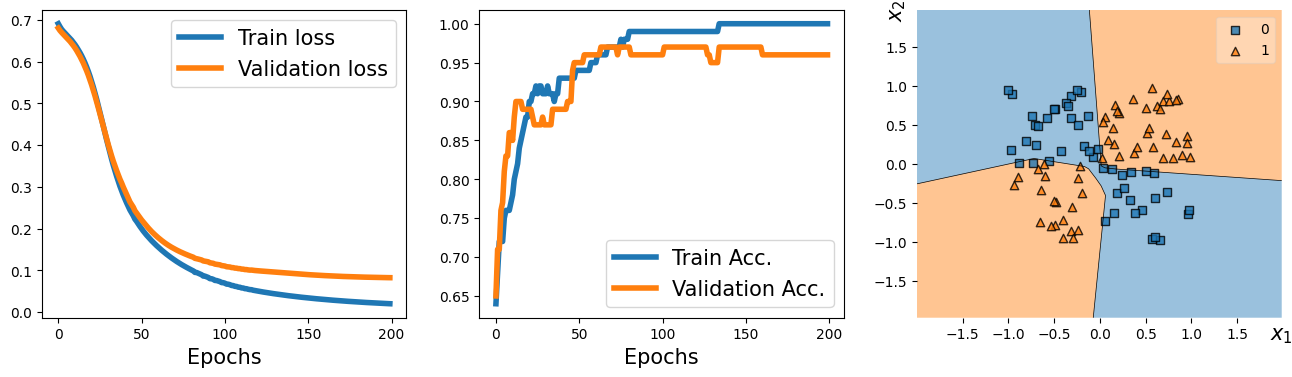

In [19]:
# week7_5.txt
history = hist.history

fig = plt.figure(figsize=(16, 4))
ax = fig.add_subplot(1, 3, 1)
plt.plot(history['loss'], lw=4)
plt.plot(history['val_loss'], lw=4)
plt.legend(['Train loss', 'Validation loss'], fontsize=15)
ax.set_xlabel('Epochs', size=15)

ax = fig.add_subplot(1, 3, 2)
plt.plot(history['binary_accuracy'], lw=4)
plt.plot(history['val_binary_accuracy'], lw=4)
plt.legend(['Train Acc.', 'Validation Acc.'], fontsize=15)
ax.set_xlabel('Epochs', size=15)

ax = fig.add_subplot(1, 3, 3)
plot_decision_regions(X=x_valid, y=y_valid.astype(np.int64),
                      clf=model_mlp3)
ax.set_xlabel(r'$x_1$', size=15)
ax.xaxis.set_label_coords(1, -0.025)
ax.set_ylabel(r'$x_2$', size=15)
ax.yaxis.set_label_coords(-0.025, 1)
plt.show()

In [20]:
class NoisyLinear(tf.keras.layers.Layer):
    def __init__(self, output_dim, noise_stddev=0.1, **kwargs):
        self.output_dim = output_dim
        self.noise_stddev = noise_stddev
        super(NoisyLinear, self).__init__(**kwargs)

    def build(self, input_shape):
        self.w = self.add_weight(name='weights',
                                 shape=(input_shape[1], self.output_dim),
                                 initializer='random_normal',
                                 trainable=True)

        self.b = self.add_weight(shape=(self.output_dim,),
                                 initializer='zeros',
                                 trainable=True)

    def call(self, inputs, training=False):
        if training:
            batch = tf.shape(inputs)[0]
            dim = tf.shape(inputs)[1]
            noise = tf.random.normal(shape=(batch, dim),
                                     mean=0.0,
                                     stddev=self.noise_stddev)

            noisy_inputs = tf.add(inputs, noise)
        else:
            noisy_inputs = inputs
        z = tf.matmul(noisy_inputs, self.w) + self.b
        return tf.keras.activations.relu(z)

    def get_config(self):
        config = super(NoisyLinear, self).get_config()
        config.update({'output_dim': self.output_dim,
                       'noise_stddev': self.noise_stddev})
        return config

In [21]:
tf.random.set_seed(1)

# 사용자 정의 레이어 객체 생성
noisy_layer = NoisyLinear(4)
noisy_layer.build(input_shape=(None, 4))

x = tf.zeros(shape=(1, 4))
tf.print(noisy_layer(x, training=True)) # training=True 이므로 랜덤 노이즈 추가

## 직렬화된 객체 값 불러오기
config = noisy_layer.get_config()

new_layer = NoisyLinear.from_config(config) # 새로운 레이어를 config 를 적용하여 초기화
tf.print(new_layer(x, training=True))

[[0 0.00494033657 0.00931170862 0]]


[[0 0.00770685775 0.0123083144 0.00268908357]]


In [22]:
tf.random.set_seed(1)

model_noisylinear = tf.keras.Sequential([
    NoisyLinear(4, noise_stddev=0.1),
    tf.keras.layers.Dense(units=4, activation='relu'),
    tf.keras.layers.Dense(units=4, activation='relu'),
    tf.keras.layers.Dense(units=1, activation='sigmoid')])

model_noisylinear.build(input_shape=(None, 2))
model_noisylinear.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ noisy_linear_1 (NoisyLinear)    │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57 (228.00 B)

 Trainable params: 57 (228.00 B)

 Non-trainable params: 0 (0.00 B)

In [23]:
## 컴파일
model_noisylinear.compile(optimizer=tf.keras.optimizers.SGD(),
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=[tf.keras.metrics.BinaryAccuracy()])

## 훈련
hist = model_noisylinear.fit(x_train, y_train,
                     validation_data=(x_valid, y_valid),
                     epochs=200, batch_size=2,
                     verbose=1)

Epoch 1/200


 1/50 ━━━━━━━━━━━━━━━━━━━━ 4s 93ms/step - binary_accuracy: 0.5000 - loss: 0.6682

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.4900 - loss: 0.6838 - val_binary_accuracy: 0.5300 - val_loss: 0.6759


Epoch 2/200


 1/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - binary_accuracy: 0.5000 - loss: 0.6601

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 806us/step - binary_accuracy: 0.5300 - loss: 0.6734 - val_binary_accuracy: 0.5500 - val_loss: 0.6665


... (590 outputs left out)

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 985us/step - binary_accuracy: 0.9100 - loss: 0.1908 - val_binary_accuracy: 0.9300 - val_loss: 0.2142


Epoch 200/200


 1/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - binary_accuracy: 0.5000 - loss: 1.4562

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - binary_accuracy: 0.9400 - loss: 0.1732 - val_binary_accuracy: 0.9100 - val_loss: 0.2113


    1/20000 ━━━━━━━━━━━━━━━━━━━━ 8:48 26ms/step

  258/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 195us/step 

  523/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 192us/step

  810/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 186us/step

 1078/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 186us/step

 1355/20000 ━━━━━━━━━━━━━━━━━━━━ 3s 185us/step

... (65 outputs left out)

19294/20000 ━━━━━━━━━━━━━━━━━━━━ 0s 184us/step

19558/20000 ━━━━━━━━━━━━━━━━━━━━ 0s 184us/step

19823/20000 ━━━━━━━━━━━━━━━━━━━━ 0s 184us/step

20000/20000 ━━━━━━━━━━━━━━━━━━━━ 4s 185us/step


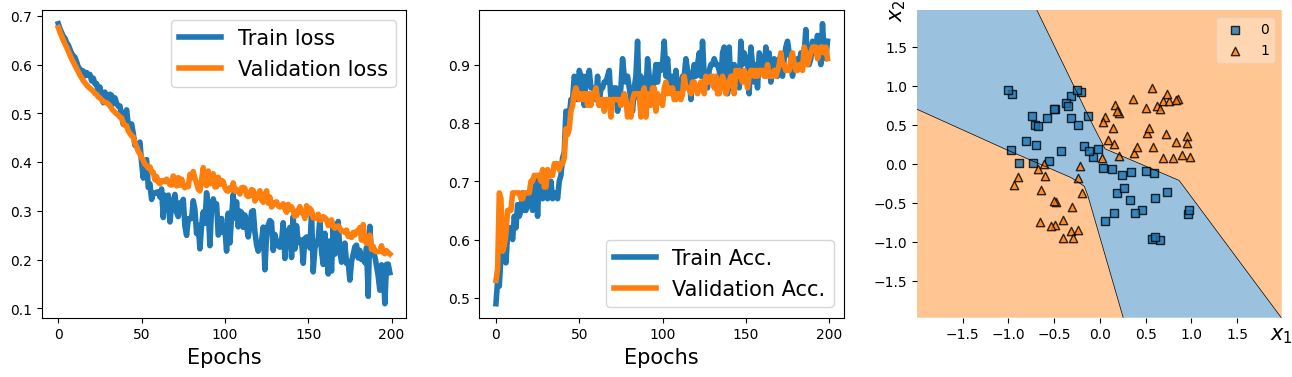

In [24]:
# week7_6.txt
history = hist.history

fig = plt.figure(figsize=(16, 4))
ax = fig.add_subplot(1, 3, 1)
plt.plot(history['loss'], lw=4)
plt.plot(history['val_loss'], lw=4)
plt.legend(['Train loss', 'Validation loss'], fontsize=15)
ax.set_xlabel('Epochs', size=15)

ax = fig.add_subplot(1, 3, 2)
plt.plot(history['binary_accuracy'], lw=4)
plt.plot(history['val_binary_accuracy'], lw=4)
plt.legend(['Train Acc.', 'Validation Acc.'], fontsize=15)
ax.set_xlabel('Epochs', size=15)

ax = fig.add_subplot(1, 3, 3)
plot_decision_regions(X=x_valid, y=y_valid.astype(np.int64),
                      clf=model_noisylinear)
ax.set_xlabel(r'$x_1$', size=15)
ax.xaxis.set_label_coords(1, -0.025)
ax.set_ylabel(r'$x_2$', size=15)
ax.yaxis.set_label_coords(-0.025, 1)
# plt.savefig('images/14_4.png', dpi=300)
plt.show()